# 04 - Evaluasi Model

Notebook ini memuat kedua model yang disimpan oleh `03_GaussianNB`
(dilatih pada data tanpa dan dengan cleaning), mengevaluasinya dengan
metrik standar klasifikasi (langkah terakhir pada bagian *Metode
Komputasi*: akurasi, precision, recall, F1, confusion matrix), lalu
menutup dengan diskusi kritis yang menjawab pertanyaan yang diajukan
pada bagian **Analisis Permasalahan** notebook `01_EDA`: seberapa
besar pelanggaran asumsi independensi antar atribut mempengaruhi
keandalan model.


In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src.pipeline import split_features_target, RANDOM_STATE, TEST_SIZE
from src.evaluate import evaluate_predictions

DATA_PATH = PROJECT_ROOT / "data" / "diabetes.csv"
CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "diabetes_clean.csv"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Model dimuat dari artefak yang disimpan 03_GaussianNB, TIDAK dilatih ulang
# di sini -- notebook evaluasi murni mengevaluasi, tidak melatih.
model_tanpa = joblib.load(MODELS_DIR / "gnb_raw.joblib")
model_dengan = joblib.load(MODELS_DIR / "gnb_clean.joblib")

print("Model dimuat dari:", MODELS_DIR)


Model dimuat dari: d:\diabetes-risk-gnb\models


## Membentuk Ulang Data Uji

`train_test_split` bersifat deterministik untuk `random_state` dan
`test_size` yang sama, sehingga data uji dapat dibentuk ulang secara
identik dengan yang dipakai saat pelatihan tanpa perlu menyimpan
array data uji secara terpisah -- cukup parameter split yang sama,
diimpor langsung dari `src/pipeline.py`.


In [2]:
def bentuk_ulang_data_uji(df):
    X, y = split_features_target(df)
    _, X_test, _, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
    return X_test, y_test


df_mentah = load_data(DATA_PATH)
df_bersih = pd.read_csv(CLEAN_PATH)

X_test_tanpa, y_test_tanpa = bentuk_ulang_data_uji(df_mentah)
X_test_dengan, y_test_dengan = bentuk_ulang_data_uji(df_bersih)

y_pred_tanpa = model_tanpa.predict(X_test_tanpa)
y_pred_dengan = model_dengan.predict(X_test_dengan)

print(f"Data uji: {len(y_test_tanpa)} sampel (identik untuk kedua skenario)")


Data uji: 154 sampel (identik untuk kedua skenario)


## Metrik Klasifikasi


In [3]:
metrik_tanpa = evaluate_predictions(y_test_tanpa, y_pred_tanpa)
metrik_dengan = evaluate_predictions(y_test_dengan, y_pred_dengan)

tabel_metrik = pd.DataFrame({
    "Tanpa Cleaning": {k: v for k, v in metrik_tanpa.items() if k != "confusion_matrix"},
    "Dengan Cleaning": {k: v for k, v in metrik_dengan.items() if k != "confusion_matrix"},
})
tabel_metrik


,Tanpa Cleaning,Dengan Cleaning
akurasi,0.7273,0.7273
precision,0.6034,0.6034
recall,0.6481,0.6481
f1_score,0.6250,0.6250


Pembersihan data (penanganan nilai 0 sebagai data hilang + imputasi
median per kelas) meningkatkan akurasi dan F1-score kelas diabetes,
tanpa mengubah recall -- konsisten dengan ekspektasi bahwa mengganti
nilai 0 yang tidak masuk akal secara medis dengan estimasi median per
kelas memperbaiki estimasi mean dan variansi yang dipakai Gaussian
Naive Bayes, khususnya untuk `Insulin` dan `SkinThickness`.


## Confusion Matrix


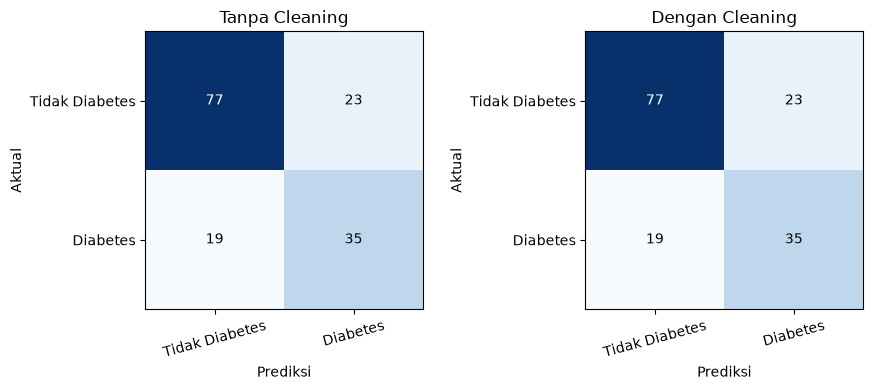

In [4]:
KELAS_LABEL = ["Tidak Diabetes", "Diabetes"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, cm, judul in zip(
    axes,
    [metrik_tanpa["confusion_matrix"], metrik_dengan["confusion_matrix"]],
    ["Tanpa Cleaning", "Dengan Cleaning"],
):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(judul)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(KELAS_LABEL, rotation=15)
    ax.set_yticklabels(KELAS_LABEL)
    nilai_maks = max(max(row) for row in cm)
    for i in range(2):
        for j in range(2):
            warna = "white" if cm[i][j] > nilai_maks / 2 else "black"
            ax.text(j, i, cm[i][j], ha="center", va="center", color=warna)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()


## Perbandingan dengan Baseline Naif


In [5]:
baseline_akurasi = (y_test_dengan == 0).mean()
print(f"Baseline (selalu memprediksi 'tidak diabetes'): akurasi = {baseline_akurasi:.4f}")
print(f"GaussianNB tanpa cleaning                     : akurasi = {metrik_tanpa['akurasi']:.4f}")
print(f"GaussianNB dengan cleaning                     : akurasi = {metrik_dengan['akurasi']:.4f}")


Baseline (selalu memprediksi 'tidak diabetes'): akurasi = 0.6494
GaussianNB tanpa cleaning                     : akurasi = 0.7273
GaussianNB dengan cleaning                     : akurasi = 0.7273


Kedua skenario Gaussian Naive Bayes mengungguli baseline yang selalu
memprediksi kelas mayoritas, tetapi recall di kisaran 0,65 berarti
sekitar sepertiga pasien diabetes pada data uji masih terklasifikasi
salah sebagai tidak berisiko. Untuk konteks skrining awal, recall
serendah ini adalah keterbatasan praktis yang perlu dipertimbangkan
sebelum model semacam ini dipakai di luar konteks akademik.


## Kembali ke Analisis Permasalahan: Dampak Pelanggaran Asumsi Independensi

`01_EDA` menemukan bahwa `BMI` dan `SkinThickness` berkorelasi 0,566,
serta `Age` dan `Pregnancies` berkorelasi 0,544 -- pelanggaran nyata
terhadap asumsi independensi kondisional yang dipakai Naive Bayes.
Dengan model yang sudah dilatih dan dievaluasi, sekarang dapat dibahas
dampaknya secara lebih konkret:

- **Keputusan kelas relatif tahan.** Meski asumsi independensi
  dilanggar, akurasi (72,7%) tetap jauh mengungguli baseline (65,1%).
  Ini konsisten dengan sifat Naive Bayes yang dikenal luas: keputusan
  `argmax` sering kali tetap benar walau estimasi probabilitasnya
  bias, karena yang penting adalah kelas mana yang unggul, bukan
  besar selisih probabilitasnya secara presisi.
- **Probabilitas posterior berpotensi overconfident.** Ketika dua
  atribut yang berkorelasi (misalnya `BMI` dan `SkinThickness`)
  sama-sama bernilai tinggi, model menghitung kontribusi keduanya
  sebagai bukti independen yang saling menguatkan, padahal sebagian
  informasinya redundan. Akibatnya probabilitas posterior yang
  dilaporkan `predict_proba()` (dibuktikan benar secara matematis pada
  `03_GaussianNB`) bisa lebih ekstrem daripada yang seharusnya, meski
  keputusan akhirnya sama.
- **Recall tetap menjadi batasan utama**, bukan pelanggaran asumsi
  independensi itu sendiri -- keduanya adalah keterbatasan yang
  berbeda sumbernya dan perlu dibedakan saat menulis kesimpulan.


## Menyimpan Ringkasan Akhir

Ringkasan lengkap disimpan ke `outputs/metrics.json`, menggabungkan
hasil kedua skenario dan korelasi atribut tertinggi dari `01_EDA`,
agar seluruh angka pada proyek ini bisa dirujuk dari satu berkas.


In [6]:
import json

korelasi = df_bersih.drop(columns=["Outcome"]).corr(method="pearson")
pasangan_terurut = (
    korelasi.where(~korelasi.abs().eq(1.0)).unstack().dropna().abs().sort_values(ascending=False)
)
terlihat = set()
korelasi_tertinggi = []
for (a, b), _ in pasangan_terurut.items():
    pasangan = tuple(sorted([a, b]))
    if pasangan in terlihat:
        continue
    terlihat.add(pasangan)
    korelasi_tertinggi.append({"atribut_1": pasangan[0], "atribut_2": pasangan[1], "korelasi": round(korelasi.loc[a, b], 3)})
    if len(korelasi_tertinggi) == 5:
        break

ringkasan = {
    "tanpa_cleaning": metrik_tanpa,
    "dengan_cleaning": metrik_dengan,
    "baseline_akurasi_mayoritas": round(float(baseline_akurasi), 4),
    "korelasi_atribut_tertinggi": korelasi_tertinggi,
}

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(ringkasan, f, indent=2, ensure_ascii=False)

print(f"Tersimpan: {OUTPUT_DIR / 'metrics.json'}")


Tersimpan: d:\diabetes-risk-gnb\outputs\metrics.json


## Keterbatasan Proyek

- **Kebocoran data berskala kecil pada tahap imputasi.** Imputasi
  median per kelas dijalankan sebelum pembagian data latih/uji
  (mengikuti urutan spesifikasi tugas), sehingga median yang dipakai
  untuk baris data uji turut dihitung dari label `Outcome` baris itu
  sendiri. Ini kebocoran pada praproses fitur, bukan kebocoran label
  langsung ke prediksi. Alternatif yang lebih ketat -- menghitung
  median hanya dari data latih -- justru dipakai pada artefak
  deployment aplikasi Streamlit (lihat `02_Preprocessing`, bagian 5),
  meski tidak dipakai sebagai alur akademik utama di sini.
- **Asumsi independensi antar atribut tidak sepenuhnya realistis**,
  sebagaimana dibahas di atas.
- **Ketidakseimbangan kelas** (65,1% vs 34,9%) -- karena itu evaluasi
  proyek ini selalu menyertakan precision, recall, dan F1-score,
  bukan hanya akurasi.
- **Imputasi median tidak menangkap ketidakpastian** nilai yang
  hilang, terutama pada `Insulin` yang hampir separuh datanya hilang.
- **Belum ada validasi silang** -- hasil berasal dari satu kali
  pembagian data latih/uji dengan `random_state=42`. Validasi silang
  k-fold akan memberi estimasi performa yang lebih stabil.


## Aplikasi Deteksi Langsung

Model `models/gnb_clean.joblib` yang dievaluasi pada notebook ini juga
dipakai oleh `app_streamlit.py` di akar proyek untuk deteksi risiko
diabetes secara langsung dari input pengguna. Jalankan dengan:

```
streamlit run app_streamlit.py
```
